# Comparación de modelos de minería de datos

Este notebook evalúa los modelos guardados en `models/` sobre el mismo conjunto de test cronológico (`data/test_data.npz`). El archivo conserva las particiones train/validación/test para reproducir los preprocesadores sin ajustar transformaciones con datos de test.

La etiqueta común es `hay_cola = pct_posible_cola > 0.5`. Los resultados finales se calculan sobre la intersección exacta de filas de test para las que los cinco modelos producen una predicción.

## Preparación específica por modelo

In [6]:
from pathlib import Path
import sys

_evaluation_dir = next(
    (
        candidate
        for base in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            base if base.name == "evaluation" and (base / "setup.py").is_file() else base / "notebooks" / "evaluation",
        )
        if (candidate / "setup.py").is_file()
    ),
    None,
)
if _evaluation_dir is None:
    raise FileNotFoundError("No se encontró notebooks/evaluation/setup.py")
if str(_evaluation_dir) not in sys.path:
    sys.path.insert(0, str(_evaluation_dir))

import importlib
import setup as _setup
_setup = importlib.reload(_setup)
common_test_rows = _setup.common_test_rows
load_test_data = _setup.load_test_data
prepare_models = _setup.prepare_models

data = load_test_data()
models, predictions = prepare_models(data)

Datos: 179,850 filas; train=125,892, validación=26,979, test=26,979
Test cronológico: 2025-06-27 15:30:00 -> 2025-12-31 23:30:00
Modelos disponibles: ['gru/gru_E2_w48.keras', 'gru/gru_E2_w48_scaler.joblib', 'logistic-regression/logistic_regresion.keras', 'logistic-regression/logistic_regresion_preprocessor.joblib', 'lstm/lstm_model.keras', 'lstm/preprocessor.joblib', 'mlp/mlp_classifier.joblib', 'tcn/tcn_classification_base_w48.keras', 'tcn/tcn_classification_base_w48_scaler.joblib']


c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to

Variables de entrada: {'Regresión logística': 25, 'LSTM': (48, 30), 'GRU/TCN': (48, 27), 'MLPClassifier': 41}
Filas de test con predicción por modelo: {'GRU': 26979, 'TCN': 26979, 'LSTM': 26979, 'Regresión logística': 26979, 'MLPClassifier': 26979}


## Métricas y comparación

Filas de test compartidas: 26,979 de 26,979


,Filas,Umbral,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Modelo,,,,,,,,
Regresión logística (umbral 0.2095),26979,0.209485,0.7155,0.6854,0.9342,0.7907,0.7615,0.7715
LSTM (umbral 0.6601),26979,0.66011,0.6575,0.6322,0.9678,0.7648,0.6653,0.6848
GRU (umbral 0.35),26979,0.35,0.6555,0.6366,0.9348,0.7574,0.6758,0.7066
SARIMA,26979,por robot,0.6147,0.6040,0.9588,0.7412,0.6709,0.7020
ARIMA,26979,por robot,0.5753,0.5753,1.0000,0.7304,0.6514,0.7111
MLPClassifier,26979,0.5,0.5941,0.6516,0.6328,0.6421,0.6219,0.6551
GRU,26979,0.5,0.6144,0.6913,0.5960,0.6401,0.6758,0.7066
TCN (fuga temporal),26979,0.5,0.5932,0.7268,0.4693,0.5703,0.6936,0.7248
Regresión logística,26979,0.5,0.4813,0.8325,0.1232,0.2147,0.7615,0.7715



Métricas ARIMA/SARIMA con el protocolo del notebook de modelado (26,979 filas):


,Precisión,Recall,F1,MAE,RMSE,R²
Modelo,,,,,,
Persistencia,0.6674,0.6674,0.6674,0.3383,0.4620,-0.4200
ARIMA,0.5753,1.0000,0.7304,0.3179,0.3733,0.0730
SARIMA,0.6040,0.9588,0.7412,0.3728,0.4283,-0.2208
Mismo bloque ayer,0.6503,0.6488,0.6496,0.3397,0.4723,-0.4841
Siempre cola,0.5753,1.0000,0.7304,NaN,NaN,NaN


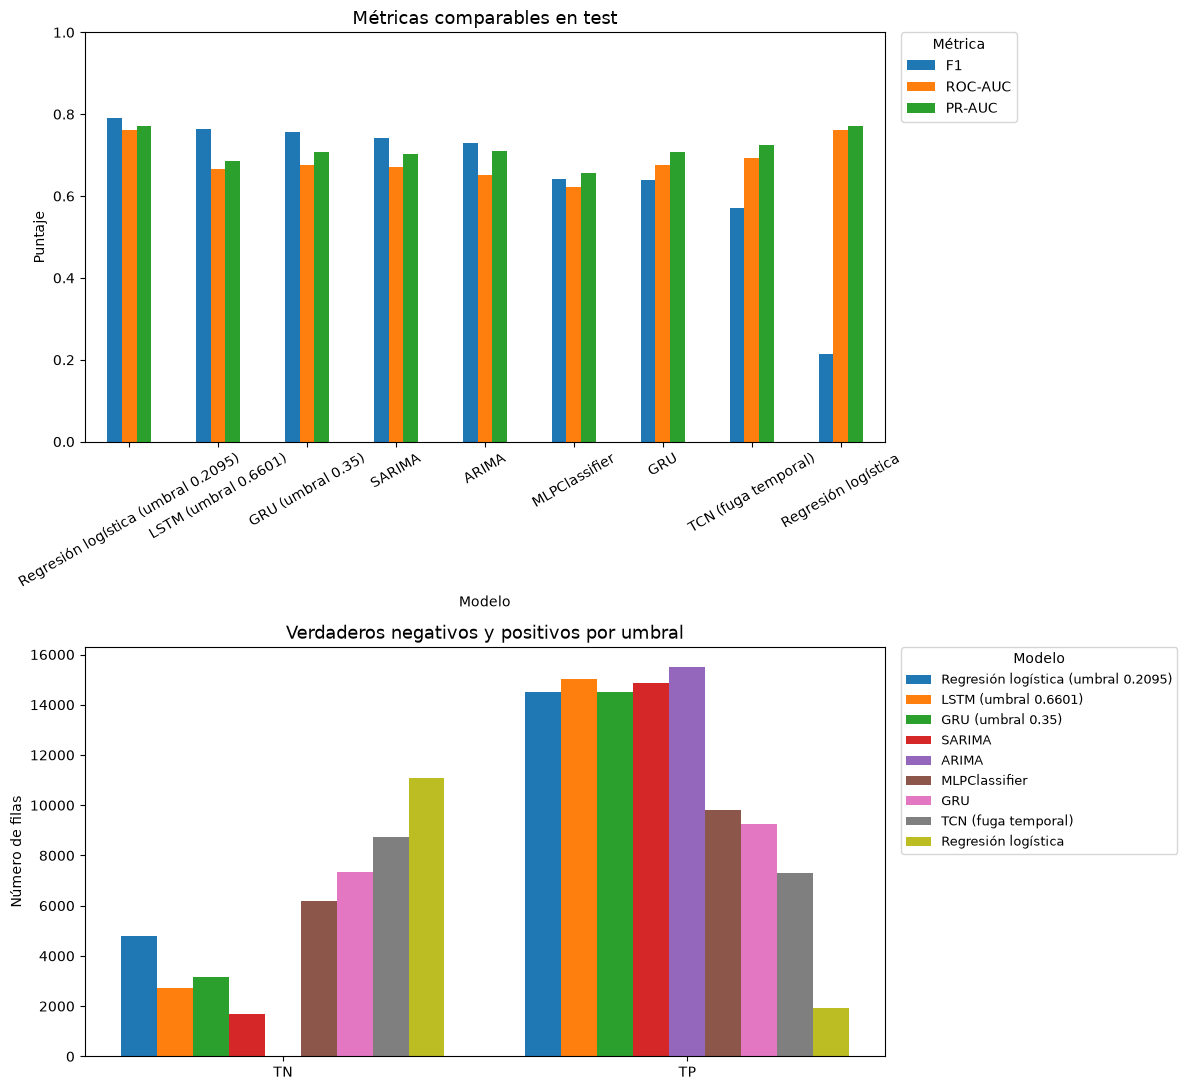

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from setup_arima_sarima import evaluate_arima_sarima

THRESHOLD = data.label_threshold

common_rows = common_test_rows(data, predictions)
actual = data.actual_labels(common_rows)

evaluation_scores = dict(predictions)
evaluation_scores["TCN (fuga temporal)"] = evaluation_scores.pop("TCN")
evaluation_thresholds = {name: THRESHOLD for name in predictions}
evaluation_thresholds["TCN (fuga temporal)"] = evaluation_thresholds.pop("TCN")
lstm_validation_name = f"LSTM (umbral {data.lstm_decision_threshold:.4f})"
evaluation_scores[lstm_validation_name] = evaluation_scores.pop("LSTM")
evaluation_thresholds.pop("LSTM")
evaluation_thresholds[lstm_validation_name] = data.lstm_decision_threshold
gru_validation_name = f"GRU (umbral {data.gru_decision_threshold:.2f})"
evaluation_scores[gru_validation_name] = predictions["GRU"]
evaluation_thresholds[gru_validation_name] = data.gru_decision_threshold
logistic_validation_name = (
    f"Regresión logística (umbral {data.logistic_decision_threshold:.4f})"
)
evaluation_scores[logistic_validation_name] = predictions["Regresión logística"]
evaluation_thresholds[logistic_validation_name] = data.logistic_decision_threshold

arima_predictions, arima_metrics = evaluate_arima_sarima(data)
arima_indexed = arima_predictions.set_index("__row_id__")
evaluation_labels = {
    name: (scores >= evaluation_thresholds[name]).astype(np.int32)
    for name, scores in evaluation_scores.items()
}
for family in ("ARIMA", "SARIMA"):
    family_predictions = arima_indexed.loc[arima_indexed["Modelo"] == family]
    evaluation_scores[family] = family_predictions["Prediccion"]
    evaluation_labels[family] = family_predictions["Cola_predicha"]
    evaluation_thresholds[family] = "por robot"

metrics = []
for model_name, scores in evaluation_scores.items():
    y_score = scores.loc[common_rows].to_numpy(dtype=float)
    y_pred = evaluation_labels[model_name].loc[common_rows].to_numpy(dtype=np.int32)
    metrics.append({
        "Modelo": model_name,
        "Filas": len(common_rows),
        "Umbral": evaluation_thresholds[model_name],
        "Accuracy": accuracy_score(actual, y_pred),
        "Precision": precision_score(actual, y_pred, zero_division=0),
        "Recall": recall_score(actual, y_pred, zero_division=0),
        "F1": f1_score(actual, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(actual, y_score),
        "PR-AUC": average_precision_score(actual, y_score),
    })

results = pd.DataFrame(metrics).set_index("Modelo").sort_values("F1", ascending=False)
print(f"Filas de test compartidas: {len(common_rows):,} de {len(data.test):,}")
display(results.round(4))

print(f"\nMétricas ARIMA/SARIMA con el protocolo del notebook de modelado ({int(arima_metrics.loc['ARIMA', 'N']):,} filas):")
arima_report = arima_metrics.loc[
    ["Persistencia", "ARIMA", "SARIMA", "Mismo bloque ayer", "Siempre cola"],
    ["Precision", "Recall", "F1", "MAE", "RMSE", "R2"],
].rename(columns={"Precision": "Precisión", "R2": "R²"})
display(arima_report.round(4))

# --- SECCIÓN DE GRÁFICAS MODIFICADA ---
# 2 filas, 1 columna, y mayor tamaño (12 de ancho x 11 de alto)
fig, axes = plt.subplots(2, 1, figsize=(12, 11))

# Gráfica 1 (Superior)
results[["F1", "ROC-AUC", "PR-AUC"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Métricas comparables en test", fontsize=13)
axes[0].set_ylabel("Puntaje")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=30)
# Leyenda afuera a la derecha
axes[0].legend(
    title="Métrica",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
)

# Gráfica 2 (Inferior)
confusion_axes = axes[1]
width = 0.8 / len(results.index)
for offset, model_name in enumerate(results.index):
    y_pred = evaluation_labels[model_name].loc[common_rows].to_numpy(dtype=np.int32)
    cm = confusion_matrix(actual, y_pred, labels=[0, 1]).ravel()
    x = np.arange(2) + (offset - (len(results.index) - 1) / 2) * width
    confusion_axes.bar(x, cm[[0, 3]], width=width, label=model_name)

confusion_axes.set_xticks([0, 1], ["TN", "TP"])
confusion_axes.set_title("Verdaderos negativos y positivos por umbral", fontsize=13)
confusion_axes.set_ylabel("Número de filas")
# Leyenda afuera a la derecha
confusion_axes.legend(
    title="Modelo",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
    fontsize=9,
)

plt.tight_layout()
plt.show()